# Does a bigger leaderboard hold up to run luck?

- This notebook adds 3 models to the 3 of phase 1 and checks whether a
  leaderboard of 6 models can be read from 1 run
  - It is Study D of `preregistration_2.md`, whose design and predictions
    were committed before any phase-2 answer was scored
  - The new models are DeepSeek-Coder 6.7B, Llama 3.1 8B, and CodeGemma 7B,
    with 1 greedy run and 3 runs at 0.8 on both benchmarks
  - On MBPP+, Llama 3.1 8B, CodeGemma 7B, and the DeepSeek-Coder 1.3B of
    phase 1 have published scores within 2.1 points of each other
- The pedagogical arc:
  - The greedy scores of the new models against the published ones
  - How much of their variance is run-to-run luck
  - Whether the 3 close models on MBPP+ can be told apart
  - How often a 1-run leaderboard of the 6 models keeps their order
  - Which predictions held

In [1]:
%load_ext autoreload
%autoreload 2

import logging

In [2]:
import helpers.hnotebook as hnotebook

import skill_vs_luck_runs_utils as rutils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
rutils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO  > /usr/local/lib/python3.12/site-packages/ipykernel_launcher.py -f /tmp/tmp6t8julhq.json --HistoryManager.hist_file=:memory:


# Part 1: The new models

## Cell 1.1: Load the scores of both phases

- The 6-model leaderboard uses the one-shot scaffold at temperature 0.8 with
  the first 3 runs of every model, so all the models have the same number of
  runs

In [3]:
# Read the local scores of both phases and the settings of the analysis.
PHASE_1_DIR = "data/coding_runs"
PHASE_2_DIR = "data/coding_runs_phase2"
BENCHMARKS = ["humaneval", "mbpp"]
TEMPERATURE = 0.8
N_RUNS = 3
NEW_MODELS = list(rutils.PHASE_2_MODELS)
ALL_MODELS = list(rutils.PHASE_1_MODELS) + NEW_MODELS
old_scores = rutils.load_scores(PHASE_1_DIR, pattern="local_*.csv.gz")
new_scores = rutils.load_scores(PHASE_2_DIR)
scores = rutils.combine_scores(old_scores, new_scores)
new_models = scores[scores["model"].isin(NEW_MODELS)]

print("scores.shape=", scores.shape)
display(rutils.compute_score_table(new_models).round(3))
# Outcome: the greedy one-shot plus scores of the new models are 71.3 on
# HumanEval+ and 63.8 on MBPP+ for DeepSeek-Coder 6.7B, 64.0 and 63.2 for Llama
# 3.1 8B, and 51.2 and 56.3 for CodeGemma 7B. At 0.8 every new agent scores 1.1
# to 6.7 points below its greedy score.

scores.shape= (36456, 19)


n_tasks  n_runs  base_pass  plus_pass  mean_attempts  mean_seconds
source benchmark model                               temperature scaffold                                                                    
local  humaneval codegemma:7b-instruct-q4_K_M        0.0         one_shot      164       1      0.573      0.512          1.000        19.867
                                                                 repair        164       1      0.585      0.524          1.287        24.653
                                                     0.8         one_shot      164       3      0.551      0.472          1.000        20.381
                                                                 repair        164       3      0.571      0.484          1.280        25.661
                 deepseek-coder:6.7b-instruct-q4_K_M 0.0         one_shot      164       1      0.768      0.713          1.000         8.669
                                                                 repair        164       1      0.787      0.732          1.116         9.702
                                                     0.8         one_shot      164       3      0.742      0.667          1.000         9.848
                                                                 repair        164       3      0.758      0.677          1.138        11.373
                 llama3.1:8b-instruct-q4_K_M         0.0         one_shot      164       1      0.695      0.640          1.000        12.112
                                                                 repair        164       1      0.707      0.646          1.152        14.161
                                                     0.8         one_shot      164       3      0.630      0.573          1.000        13.979
                                                                 repair        164       3      0.673      0.606          1.213        17.368
       mbpp      codegemma:7b-instruct-q4_K_M        0.0         one_shot      378       1      0.672      0.563          1.000        14.105
                                                                 repair        378       1      0.685      0.571          1.283        18.062
                                                     0.8         one_shot      378       3      0.671      0.549          1.000        11.855
                                                                 repair        378       3      0.683      0.560          1.284        15.245
                 deepseek-coder:6.7b-instruct-q4_K_M 0.0         one_shot      378       1      0.730      0.638          1.000         6.201
                                                                 repair        378       1      0.749      0.651          1.225         7.877
                                                     0.8         one_shot      378       3      0.704      0.610          1.000         7.293
                                                                 repair        378       3      0.725      0.630          1.255         9.427
                 llama3.1:8b-instruct-q4_K_M         0.0         one_shot      378       1      0.735      0.632          1.000        10.398
                                                                 repair        378       1      0.757      0.638          1.214        12.961
                                                     0.8         one_shot      378       3      0.713      0.600          1.000         9.697
                                                                 repair        378       3      0.750      0.621          1.248        12.531

## Cell 1.2: Greedy scores against the published ones

- As in phase 1, the greedy one-shot run checks the harness against the
  published EvalPlus scores, which use full-precision weights

In [4]:
# Compare the greedy one-shot scores of the new models with the published ones.
validation = rutils.compute_validation_table(new_models)

display(validation.round(3))
# Outcome: 5 of the 6 greedy scores are within 2 points of the published ones,
# DeepSeek-Coder 6.7B on HumanEval+ exactly, but Llama 3.1 8B gets 63.2 on
# MBPP+ against a published 55.6 (+7.6 points), while it matches on HumanEval+
# (+1.2).

n_tasks  base_pass  plus_pass  published_base  published_plus  plus_diff
model                               benchmark                                                                          
codegemma:7b-instruct-q4_K_M        humaneval      164      0.573      0.512           0.604           0.518     -0.006
                                    mbpp           378      0.672      0.563           0.704           0.569     -0.006
deepseek-coder:6.7b-instruct-q4_K_M humaneval      164      0.768      0.713           0.744           0.713      0.000
                                    mbpp           378      0.730      0.638           0.749           0.656     -0.018
llama3.1:8b-instruct-q4_K_M         humaneval      164      0.695      0.640           0.695           0.628      0.012
                                    mbpp           378      0.735      0.632           0.683           0.556      0.076

# Part 2: How much of the variance is run luck?

## Cell 2.1: Task and run parts of the variance of the new agents

- Not a prediction of Study D: the same split as in phase 1, from the 3 runs
  at 0.8 of each new agent
  - These run shares are also the truth of the phase-2 cases of Study B

In [5]:
# Split the variance of every new agent, on each benchmark.
variance = {
    benchmark: rutils.compute_variance_table(
        new_models,
        source="local",
        benchmark=benchmark,
        temperature=TEMPERATURE,
    )
    for benchmark in BENCHMARKS
}

for benchmark, table in variance.items():
    print("benchmark=", benchmark)
    display(table.round(4))
# Outcome: runs are 35% to 53% of the variance of 1 run on HumanEval+ and 28%
# to 35% on MBPP+, the same range as the old models at 0.8 (28% to 52%).

benchmark= humaneval


,score,sigma2_task,sigma2_run,run_share,se_1_run,se_all_runs
deepseek-coder 6.7b / repair,0.6768,0.1037,0.1159,0.5276,0.0366,0.0295
deepseek-coder 6.7b / one_shot,0.6667,0.1093,0.1138,0.5101,0.0369,0.0300
llama3.1 8b / repair,0.6057,0.1566,0.0833,0.3473,0.0383,0.0335
llama3.1 8b / one_shot,0.5732,0.1482,0.0976,0.3970,0.0387,0.0332
codegemma 7b / repair,0.4837,0.1533,0.0976,0.3889,0.0391,0.0337
codegemma 7b / one_shot,0.4715,0.1426,0.1077,0.4304,0.0391,0.0330


benchmark= mbpp


,score,sigma2_task,sigma2_run,run_share,se_1_run,se_all_runs
deepseek-coder 6.7b / repair,0.6296,0.1684,0.0653,0.2792,0.0249,0.0224
llama3.1 8b / repair,0.6208,0.1636,0.0723,0.3065,0.0250,0.0223
deepseek-coder 6.7b / one_shot,0.6102,0.1713,0.0670,0.2812,0.0251,0.0226
llama3.1 8b / one_shot,0.5996,0.1630,0.0776,0.3226,0.0252,0.0224
codegemma 7b / repair,0.5600,0.1596,0.0873,0.3536,0.0256,0.0223
codegemma 7b / one_shot,0.5494,0.1625,0.0855,0.3448,0.0256,0.0225


# Part 3: Can the 3 close models on MBPP+ be told apart?

## Cell 3.1: Paired comparisons of the cluster

- The 3 pairs of Llama 3.1 8B, CodeGemma 7B, and DeepSeek-Coder 1.3B, with
  the one-shot scaffold, over the tasks and the first 3 runs at 0.8
- The Holm adjustment covers the 3 tests

In [6]:
# Compare the 3 pairs of the MBPP+ cluster.
LLAMA = "llama3.1:8b-instruct-q4_K_M"
CODEGEMMA = "codegemma:7b-instruct-q4_K_M"
DEEPSEEK_SMALL = "deepseek-coder:1.3b-instruct-q4_K_M"
pairs = [
    ((LLAMA, "one_shot"), (CODEGEMMA, "one_shot")),
    ((LLAMA, "one_shot"), (DEEPSEEK_SMALL, "one_shot")),
    ((CODEGEMMA, "one_shot"), (DEEPSEEK_SMALL, "one_shot")),
]
first_runs = scores[scores["run"] < N_RUNS]
comparisons = rutils.compare_agent_pairs(
    first_runs,
    pairs,
    source="local",
    benchmarks=["mbpp"],
    temperature=TEMPERATURE,
)

display(comparisons.round(4))
# Outcome: in our runs the cluster is not close: Llama 3.1 8B is 5.0 points
# above CodeGemma 7B and 12.0 above DeepSeek-Coder 1.3B, and CodeGemma is 7.0
# above DeepSeek-Coder 1.3B, so all 3 pairs are distinguishable (Holm p of
# 0.0044 or less).

,benchmark,agent_a,agent_b,gap,ci_low,ci_high,gap_run_0,p_value,p_holm,distinguishable
0,mbpp,llama3.1 8b / one_shot,codegemma 7b / one_shot,0.0503,0.0176,0.0838,0.0291,0.0044,0.0044,True
1,mbpp,llama3.1 8b / one_shot,deepseek-coder 1.3b / one_shot,0.1199,0.0838,0.1605,0.0979,0.0000,0.0000,True
2,mbpp,codegemma 7b / one_shot,deepseek-coder 1.3b / one_shot,0.0697,0.0326,0.1094,0.0688,0.0003,0.0005,True


# Part 4: How stable is a 1-run leaderboard of 6 models?

## Cell 4.1: Order of the 6 models in random 1-run leaderboards on MBPP+

- A 1-run leaderboard picks 1 of the first 3 runs of each model, with the
  one-shot scaffold
- Every combination of runs is taken once (3^6 = 729), so the shares are
  exact instead of coming from random draws

In [7]:
# Draw random 1-run leaderboards of the 6 models on MBPP+.
matrices = rutils.get_first_runs_matrices(
    scores,
    models=ALL_MODELS,
    scaffold="one_shot",
    benchmark="mbpp",
    temperature=TEMPERATURE,
    n_runs=N_RUNS,
)
stability, flips = rutils.compute_ranking_stability(matrices, n_draws=None)

print("stability=", stability.round(3).to_dict())
display(flips.round(3))
# Outcome: only 44.4% of the 729 leaderboards keep the order of the 6 models.
# Every break comes from DeepSeek-Coder 6.7B and Llama 3.1 8B, 1.1 points
# apart, which swap in 5 of their 9 pairs of runs; OpenCoder 8B and CodeQwen
# 7B, 2.0 points apart, tie in 1 of 9 (a tie counts as half a swap), and no
# other pair ever swaps.

stability= {'p_same_order': 0.444, 'mean_kendall_tau': 0.922}


,upper,lower,gap,p_flip
0,deepseek-coder 6.7b / one_shot,llama3.1 8b / one_shot,0.011,0.556
1,opencoder 8b / one_shot,codeqwen 7b / one_shot,0.020,0.056
2,llama3.1 8b / one_shot,codegemma 7b / one_shot,0.050,0.000
3,codeqwen 7b / one_shot,deepseek-coder 6.7b / one_shot,0.060,0.000
4,deepseek-coder 6.7b / one_shot,codegemma 7b / one_shot,0.061,0.000
5,codegemma 7b / one_shot,deepseek-coder 1.3b / one_shot,0.070,0.000
6,codeqwen 7b / one_shot,llama3.1 8b / one_shot,0.071,0.000
7,opencoder 8b / one_shot,deepseek-coder 6.7b / one_shot,0.080,0.000
8,opencoder 8b / one_shot,llama3.1 8b / one_shot,0.091,0.000
9,llama3.1 8b / one_shot,deepseek-coder 1.3b / one_shot,0.120,0.000


## Cell 4.2: Plot of the flip rate of each pair

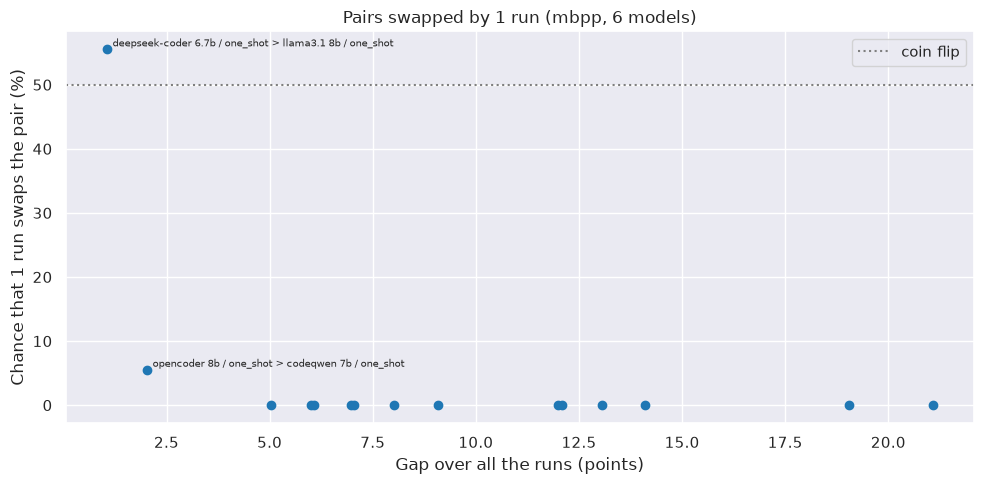

In [8]:
# Plot how often each pair swaps places, against its gap.
rutils.plot_flip_rates(
    flips, title="Pairs swapped by 1 run (mbpp, 6 models)", figsize=(10, 5)
)
# Outcome: only the 2 closest pairs ever swap, and DeepSeek-Coder 6.7B and
# Llama 3.1 8B swap in 56% of the leaderboards, above the coin-flip line.

## Cell 4.3: The same leaderboard on HumanEval+

- Not in the pre-registration: an extra look at Cell 4.1 on the other
  benchmark

In [9]:
# Draw random 1-run leaderboards of the 6 models on HumanEval+.
humaneval_matrices = rutils.get_first_runs_matrices(
    scores,
    models=ALL_MODELS,
    scaffold="one_shot",
    benchmark="humaneval",
    temperature=TEMPERATURE,
    n_runs=N_RUNS,
)
humaneval_stability, _ = rutils.compute_ranking_stability(
    humaneval_matrices, n_draws=None
)

print("humaneval_stability=", humaneval_stability.round(3).to_dict())
# Outcome: on HumanEval+, 88.9% of the leaderboards keep the order of the 6
# models, twice the share on MBPP+.

humaneval_stability= {'p_same_order': 0.889, 'mean_kendall_tau': 0.974}


# Part 5: Which predictions held?

## Cell 5.1: Predictions against the results

- The rules follow `preregistration_2.md`, which was committed before any
  phase-2 answer was scored

In [10]:
# Check each prediction of Study D.
predictions = rutils.check_new_model_predictions(
    validation=validation, comparisons=comparisons, stability=stability
)

display(predictions)
# Outcome: D3 holds and D1 and D2 do not: D1 misses on 1 of its 6 values,
# Llama 3.1 8B on MBPP+, and D2 misses because the 3 models that the published
# scores put within 2.1 points of each other are 5 to 12 points apart in our
# runs.

,prediction,observed,holds
D1,Greedy scores are within 5 points of the publi...,"5 of 6 within 5 points, largest gap +7.6 point...",False
D2,No pair of the MBPP+ cluster is distinguishable,"3 of 3 pairs distinguishable, smallest Holm p ...",False
D3,Fewer than half of the 1-run leaderboards keep...,44.4% keep the order of the 6 models,True


# Part 6: Takeaways

- With 6 models on MBPP+, fewer than half of the 1-run leaderboards (44.4%)
  keep the order, and a single pair 1.1 points apart causes every break
- The published scores did not tell which models would be close in our
  setup:
  - The 3 models within 2.1 points of each other in the published MBPP+
    scores are 5 to 12 points apart in our runs at 0.8
  - DeepSeek-Coder 6.7B and Llama 3.1 8B, 10 points apart in the published
    MBPP+ scores, are 1.1 points apart in our runs
- The harness matches 5 of the 6 published greedy scores within 2 points;
  Llama 3.1 8B on MBPP+ is 7.6 points above, and we have not found why
- The new agents have about as much run luck at 0.8 as the old ones: 28% to
  53% of the variance of 1 run